# Bitcoin Price Prediction: What Can and Cannot Be Predicted
**Author:** Victor Chigbu

**Question:** Can machine learning predict Bitcoin's price? Rather than just fitting a model and reporting a flattering number, I test three different prediction targets against honest baselines and use a time-ordered train/test split:

1. **Price level**: what will the price be tomorrow?
2. **Return and direction**: will tomorrow's price go up or down, and by how much?
3. **Volatility**: how large will price swings be over the next week?

**Data:** Daily BTC-USD closing price, open, high and low from CoinDesk (1 Oct 2013 to 18 May 2021, 2,787 days). The dataset ends in May 2021, so findings describe that period.

**Why the split matters:** with time-series data I cannot shuffle rows. The model trains on the past (2013 to 2018) and is tested on the future (2019 to 2021). Shuffling would let the model "see" days next to the ones it is predicting.

In [1]:
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, roc_auc_score)
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})

## 1. Load and check the data

In [2]:
raw = pd.read_csv('btc_usd_daily.csv', parse_dates=['Date'])
d = raw.rename(columns={'Closing Price (USD)':'close','24h Open (USD)':'open',
                        '24h High (USD)':'high','24h Low (USD)':'low'}).set_index('Date').drop(columns='Currency')
print('Rows:', len(d), '| from', d.index.min().date(), 'to', d.index.max().date())
print('Missing values:', int(d.isna().sum().sum()), '| duplicate dates:', int(d.index.duplicated().sum()))
print('Gaps between dates (days):', d.index.to_series().diff().dt.days.value_counts().to_dict())
d.describe().loc[['min','max']].round(2)

Rows: 2787 | from 2013-10-01 to 2021-05-18
Missing values: 0 | duplicate dates: 0
Gaps between dates (days): {1.0: 2786}


,close,open,high,low
min,108.58,108.58,118.68,83.33
max,63346.79,63562.67,64801.79,62094.63


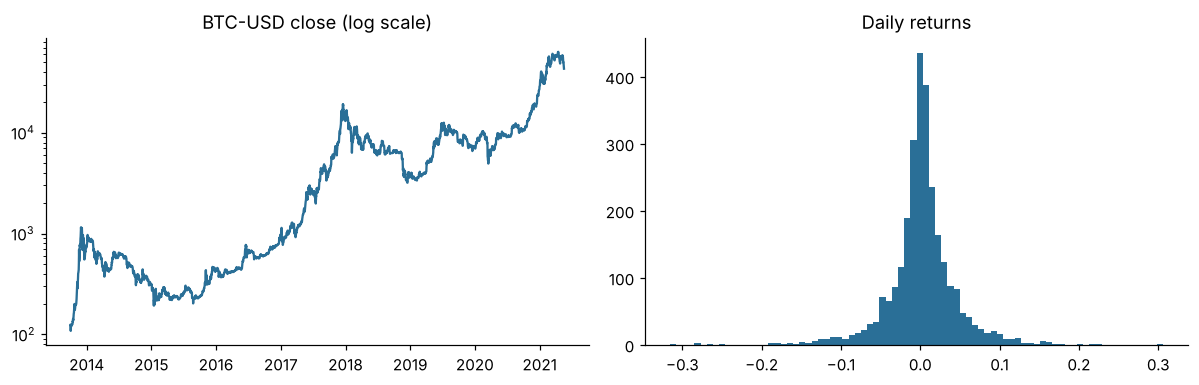

Average daily return: 0.21% | daily std: 4.27% | worst day: -31.6% | best day: 30.6%


In [3]:
d['ret'] = np.log(d['close']).diff()    # daily log return
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(d.index, d['close'], color='#2a6f97'); ax[0].set_yscale('log'); ax[0].set_title('BTC-USD close (log scale)')
ax[1].hist(d['ret'].dropna(), bins=80, color='#2a6f97'); ax[1].set_title('Daily returns'); plt.tight_layout(); plt.show()
print('Average daily return: %.2f%% | daily std: %.2f%% | worst day: %.1f%% | best day: %.1f%%' % (
      100*d.ret.mean(), 100*d.ret.std(), 100*d.ret.min(), 100*d.ret.max()))

**What stands out**
- Price rose from about $109 in late 2013 to over $63,000 in 2021, but the path was extremely rough. A typical day moves about 4.3% (the standard deviation), and the worst and best single days were -31.6% and +30.6%.
- The distribution of daily returns has fat tails: extreme days happen far more often than a bell curve would suggest. That makes any prediction harder and any single big miss costly.

## 2. Features and split
All features use only information available at the close of the day being predicted from: recent returns, how far price is from its 5-day and 20-day average, recent volatility, the day's high-low range and the day of the week. The target for each row is the **next** day's outcome.

In [4]:
f = pd.DataFrame(index=d.index)
for k in range(1, 6): f[f'ret_lag{k}'] = d['ret'].shift(k-1)       # lag1 = today's return
f['mom5']  = d['close']/d['close'].rolling(5).mean() - 1
f['mom20'] = d['close']/d['close'].rolling(20).mean() - 1
f['vol7']  = d['ret'].rolling(7).std();  f['vol30'] = d['ret'].rolling(30).std()
f['range'] = (d['high'] - d['low'])/d['open'];  f['dow'] = d.index.dayofweek
f['target_ret'] = d['ret'].shift(-1)                                 # tomorrow's return
f['target_up']  = (f['target_ret'] > 0).astype(int)
f['target_vol'] = d['ret'].rolling(7).std().shift(-7)                # volatility over the next 7 days
f['close'] = d['close']; f['next_close'] = d['close'].shift(-1)
f = f.dropna()
features = [c for c in f.columns if not c.startswith('target') and c not in ('close','next_close')]

SPLIT = '2019-01-01'
train = f[f.index < SPLIT].iloc[:-7]      # drop the last 7 training rows: their 7-day volatility target reaches into the test period
test  = f[f.index >= SPLIT]
print(len(train), 'training days (to', train.index.max().date(), ') |', len(test), 'test days (from', test.index.min().date(), ')')
print('Share of up days: train %.1f%%, test %.1f%%' % (100*train.target_up.mean(), 100*test.target_up.mean()))

1881 training days (to 2018-12-24 ) | 862 test days (from 2019-01-01 )
Share of up days: train 53.6%, test 54.4%


## 3. Target 1: predict the price level
The simplest possible forecast is **'tomorrow's price = today's price'**. I compare a model against it.

In [5]:
rf_level = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
# predict next close as a ratio to today's close so the model is not stuck below prices it has never seen
rf_level.fit(train[features], train['next_close']/train['close'])
pred_model = rf_level.predict(test[features]) * test['close']
pred_naive = test['close']
mape = lambda y, p: 100*np.mean(np.abs(y-p)/y)
level = pd.DataFrame({'Mean abs % error': [mape(test.next_close, pred_naive), mape(test.next_close, pred_model)]},
                     index=['Naive: tomorrow = today', 'Random forest']).round(2)
level

,Mean abs % error
Naive: tomorrow = today,2.47
Random forest,2.61


**Reading the result:** the random forest does **not** beat the naive forecast (2.61% average error vs 2.47%).

An average error of about 2.5% sounds impressive, and many Bitcoin price-prediction tutorials show a chart where the prediction line sits right on top of the real price. But that happens for any forecast that mostly copies today's price, because prices change only a few percent per day. The right question is whether a model beats 'tomorrow = today', and here it does not. I treat level prediction as a misleading target and move on to returns, which remove this effect.

## 4. Target 2: predict tomorrow's return and direction

In [6]:
zero = np.zeros(len(test))
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(train[features], train.target_ret)
rfr = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(train[features], train.target_ret)
rows = {}
for name, p in {'Baseline: predict 0%': zero, 'Ridge regression': ridge.predict(test[features]),
                'Random forest': rfr.predict(test[features])}.items():
    rows[name] = {'RMSE': mean_squared_error(test.target_ret, p)**.5, 'R-squared': r2_score(test.target_ret, p)}
pd.DataFrame(rows).T.round(4)

,RMSE,R-squared
Baseline: predict 0%,0.0373,-0.0073
Ridge regression,0.0373,-0.0106
Random forest,0.0381,-0.0553


**Reading the result:** neither model beats the do-nothing baseline of predicting a 0% return. R-squared is slightly below zero for every model, which means they explain none of the day-to-day movement. The random forest is worse than the baseline (RMSE 0.0381 vs 0.0373): it has fit noise in the training years that does not carry over to new data.

In [7]:
majority = max(test.target_up.mean(), 1 - test.target_up.mean())
models = {'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
          'Random forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1)}
rows, preds = {}, {}
for name, m in models.items():
    m.fit(train[features], train.target_up)
    p, pp = m.predict(test[features]), m.predict_proba(test[features])[:, 1]
    preds[name] = p
    cv_auc = cross_val_score(m, f[features], f.target_up, cv=TimeSeriesSplit(5), scoring='roc_auc').mean()
    rows[name] = {'Accuracy': accuracy_score(test.target_up, p), 'ROC AUC': roc_auc_score(test.target_up, pp),
                  'Share predicted "up"': p.mean(), 'Walk-forward CV AUC': cv_auc}
res = pd.DataFrame(rows).T.round(3)
res.loc['Baseline: always "up"'] = [majority, 0.5, 1.0, 0.5]
print('Always predicting "up" scores %.1f%% accuracy on the test period.' % (100*majority))
res

Always predicting "up" scores 54.4% accuracy on the test period.


,Accuracy,ROC AUC,"Share predicted ""up""",Walk-forward CV AUC
Logistic regression,0.548000,0.561,0.846,0.539
Random forest,0.566000,0.559,0.686,0.518
"Baseline: always ""up""",0.544084,0.500,1.000,0.500


In [8]:
n = len(test)
for name, p in preds.items():
    hits = int((p == test.target_up.values).sum())
    r = binomtest(hits, n, majority, alternative='greater')
    print('%-20s %d/%d correct (%.1f%%) | p-value vs. always-"up" baseline: %.3f' % (name, hits, n, 100*hits/n, r.pvalue))

Logistic regression  472/862 correct (54.8%) | p-value vs. always-"up" baseline: 0.433
Random forest        488/862 correct (56.6%) | p-value vs. always-"up" baseline: 0.103


**Reading the results**
- Bitcoin rose on 54.4% of test days, so a model that simply says 'up' every day is right 54.4% of the time. That is the bar to beat, not 50%.
- The random forest is right 56.6% of the time and the logistic regression 54.8%. Both are only a little above the bar. With 862 test days, a gap that small could easily be luck: the p-values against the always-'up' baseline are 0.43 and 0.10, and neither passes the usual 0.05 cut-off.
- ROC AUC is about 0.56 on the test set and drops to 0.54 and 0.52 in walk-forward cross-validation (several train/test splits moving through time). An AUC of 0.5 is a coin flip, so any signal is very weak and not stable.
- The models predict 'up' on 69% to 85% of days, because up days were more common in the training years. Much of their accuracy is just echoing that base rate.

## 5. Would it make money? A simple backtest
Hold Bitcoin on days the random forest predicts 'up', hold cash otherwise, and compare with simply buying and holding over the test period. I subtract a 0.1% fee each time the position changes. This is a rough check, not a trading strategy: no slippage, no tax and the model sees the same features I chose after looking at this history.

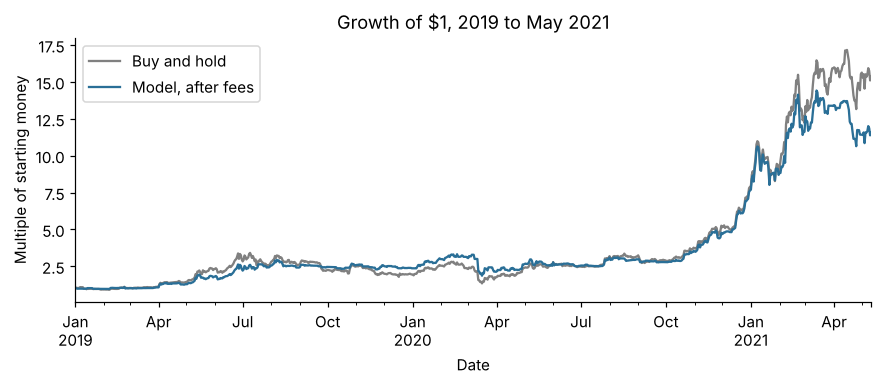

Buy and hold: $1 -> $15.33 | Model after fees: $1 -> $11.55 | days in the market: 69% | position changes: 280


In [9]:
pos = pd.Series(preds['Random forest'], index=test.index)
gross = pos * test.target_ret
fees = pos.diff().abs().fillna(0) * 0.001
net = gross - fees
bh = test.target_ret
curve = pd.DataFrame({'Buy and hold': bh.cumsum(), 'Model, after fees': net.cumsum()}).apply(np.exp)
curve.plot(figsize=(8, 3.6), color=['grey', '#2a6f97']); plt.title('Growth of $1, 2019 to May 2021'); plt.ylabel('Multiple of starting money')
plt.tight_layout(); plt.show()
print('Buy and hold: $1 -> $%.2f | Model after fees: $1 -> $%.2f | days in the market: %.0f%% | position changes: %d' % (
      np.exp(bh.sum()), np.exp(net.sum()), 100*pos.mean(), int(pos.diff().abs().sum())))

**Reading the result:** the model-based approach finished with $11.55 per $1 versus $15.33 for buy and hold. It was in the market on 69% of days and changed position 280 times, and the fees plus missed up days cost it.

The test period (2019 to May 2021) includes one of Bitcoin's strongest rallies, which makes buy and hold hard to beat for any timing strategy. That does not prove timing could never work, but it does mean this model has **not** shown an edge. I would not trade on it.

## 6. Target 3: predict volatility (the part that is predictable)
Bitcoin's swings come in clusters: calm weeks follow calm weeks and wild weeks follow wild weeks. Can a model forecast the size of the next 7 days of price moves? The baseline here is 'next week's volatility = last week's volatility'.

,RMSE,MAE,R-squared
Baseline: next week = last week,0.0214,0.0160,-0.3415
Ridge regression,0.0174,0.0131,0.1149
Random forest,0.0175,0.0136,0.1000


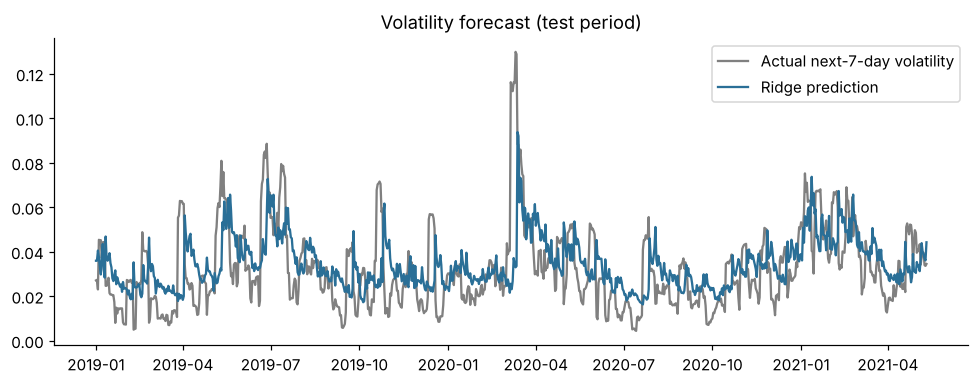

In [10]:
naive_v = test['vol7'].values
ridge_v = make_pipeline(StandardScaler(), Ridge(alpha=10)).fit(train[features], train.target_vol)
rf_v = RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=42, n_jobs=-1).fit(train[features], train.target_vol)
vp = {'Baseline: next week = last week': naive_v, 'Ridge regression': ridge_v.predict(test[features]),
      'Random forest': rf_v.predict(test[features])}
vol = pd.DataFrame({n: {'RMSE': mean_squared_error(test.target_vol, p)**.5, 'MAE': mean_absolute_error(test.target_vol, p),
                        'R-squared': r2_score(test.target_vol, p)} for n, p in vp.items()}).T.round(4)
display(vol)
plt.figure(figsize=(9, 3.6))
plt.plot(test.index, test.target_vol, label='Actual next-7-day volatility', color='grey')
plt.plot(test.index, vp['Ridge regression'], label='Ridge prediction', color='#2a6f97')
plt.legend(); plt.title('Volatility forecast (test period)'); plt.tight_layout(); plt.show()

**Reading the result:** this is where the models do add value. Predicting volatility from recent returns, ranges and volatility beats 'next week = last week' clearly: RMSE falls from 0.0214 to 0.0174 (about 19% lower) for the ridge regression, and R-squared goes from -0.34 to +0.11. The random forest is close behind (0.0175).

The improvement is real but modest: R-squared of 0.11 means most of the variation in future volatility is still unexplained. The baseline's negative R-squared shows why simple persistence is not enough, because it overreacts when a volatile week is followed by a calm one.

## 7. Conclusions
CONCLUSIONS